In [10]:
import os
import pandas as pd, numpy as np, matplotlib.pyplot as plt

FINAL = "94403ce"   # code_version of your full post-fix E1–E7 run
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("../results/timings.csv")
r = df[(df['machine_id'] == 'neil-mac') & (df['code_version'] == FINAL)].copy()
r['ns_per_op'] = r['total_ns'] / r['n_ops']
r['us_per_op'] = r['ns_per_op'] / 1000
r['cmp_per_op'] = r['comparisons'] / r['n_ops']

# sanity check: every experiment present
print(r.groupby('experiment').size())

def slope(x, y):
    """log-log slope: ~0 = O(1), ~1 = O(n), ~2 = O(n^2)"""
    return np.polyfit(np.log(x), np.log(y), 1)[0]

INDEXES = ['unsorted_list', 'sorted_list', 'hash_table', 'avl_tree', 'bplus_tree', 'ref_dict', 'ref_bisect']

experiment
E1_build_track_id       245
E2_point_track_id       490
E3_range_tempo          210
E4_prefix_track_name    175
E5_insert_order         840
E6_bplus_order          180
E7_duplicate_keys       455
example                 210
dtype: int64


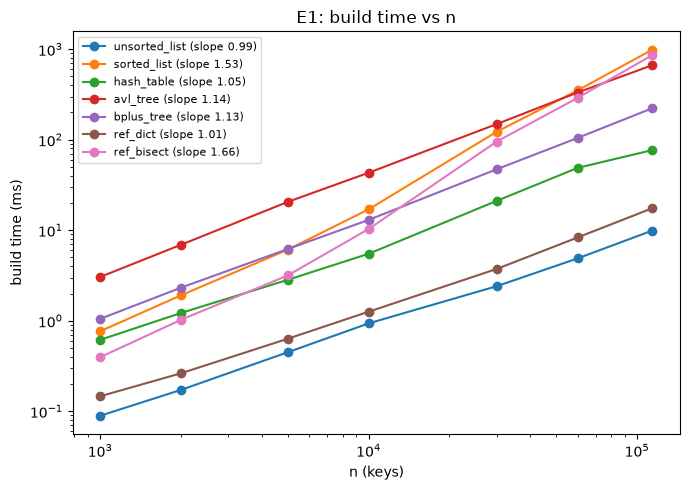

,build_ms,bytes_per_key
index_type,,
unsorted_list,9.9,65.0
ref_dict,17.5,92.0
hash_table,76.8,195.0
bplus_tree,223.0,80.0
avl_tree,666.2,115.0
ref_bisect,861.5,73.0
sorted_list,988.5,73.0


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
n_keys,,,,,,,
1000.0,7,6,4,3,2,5,1
2000.0,7,6,4,3,2,5,1
5000.0,7,6,3,4,2,5,1
10000.0,7,5,3,4,2,6,1
30000.0,7,4,3,5,2,6,1
60000.0,6,4,3,5,2,7,1
114000.0,5,4,3,6,2,7,1


In [11]:
e1 = r[r['experiment'].str.startswith('E1')]
m1 = e1.groupby(['index_type', 'n_keys']).agg(
    build_ms=('total_ns', lambda x: x.median() / 1e6),
    mem=('memory_bytes', 'median')).reset_index()

plt.figure(figsize=(7, 5))
for idx in INDEXES:
    g = m1[m1['index_type'] == idx]
    plt.loglog(g['n_keys'], g['build_ms'], 'o-', label=f"{idx} (slope {slope(g['n_keys'], g['build_ms']):.2f})")
plt.xlabel('n (keys)'); plt.ylabel('build time (ms)')
plt.title('E1: build time vs n'); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/e1_build.png', dpi=150); plt.show()

full = m1[m1['n_keys'] == m1['n_keys'].max()].set_index('index_type')
full['bytes_per_key'] = (full['mem'] / full.index.map(lambda _: m1['n_keys'].max())).round(0)
display(full[['build_ms', 'bytes_per_key']].round(1).sort_values('build_ms'))

# crossovers: rank of each index (1 = fastest build) at every n
display(m1.pivot(index='n_keys', columns='index_type', values='build_ms').rank(axis=1).astype(int))

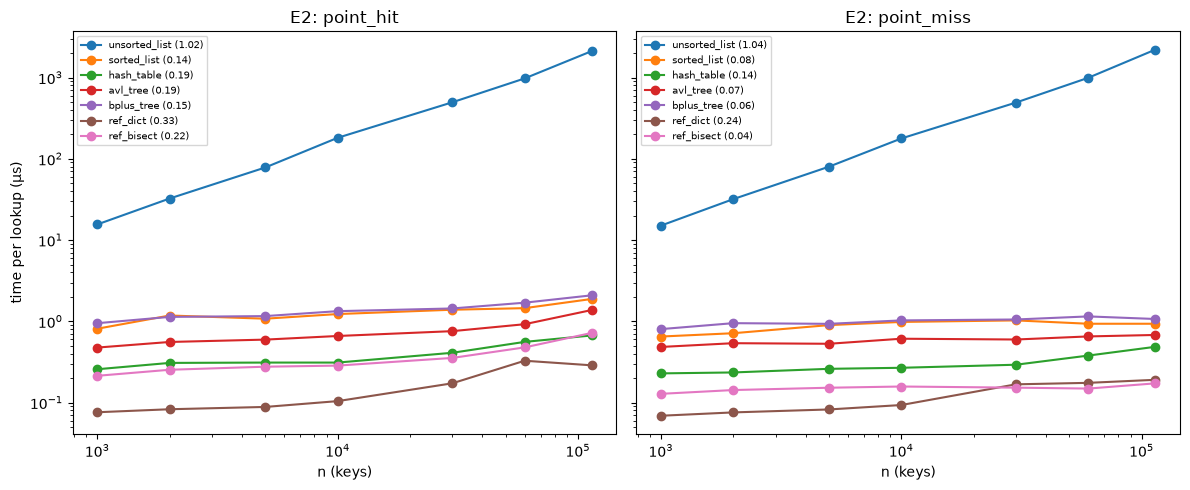

us_per_op            cmp_per_op           
operation     point_hit point_miss  point_hit point_miss
index_type                                              
avl_tree           1.38       0.68      15.73      16.00
bplus_tree         2.09       1.07      16.76      15.00
hash_table         0.67       0.49       1.34       0.65
ref_bisect         0.72       0.17        NaN        NaN
ref_dict           0.29       0.19        NaN        NaN
sorted_list        1.88       0.93      16.52      16.00
unsorted_list   2112.13    2203.03  114000.00  114000.00

index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
n_keys,,,,,,,
1000.0,4,6,3,2,1,5,7
2000.0,4,5,3,2,1,6,7
5000.0,4,6,3,2,1,5,7
10000.0,4,6,3,2,1,5,7
30000.0,4,6,3,2,1,5,7
60000.0,4,6,3,2,1,5,7
114000.0,4,6,2,3,1,5,7


In [12]:
e2 = r[r['experiment'].str.startswith('E2')]
m2 = e2.groupby(['index_type', 'operation', 'n_keys'])[['us_per_op', 'cmp_per_op']].median().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, op in zip(axes, ['point_hit', 'point_miss']):
    for idx in INDEXES:
        g = m2[(m2['index_type'] == idx) & (m2['operation'] == op)]
        ax.loglog(g['n_keys'], g['us_per_op'], 'o-', label=f"{idx} ({slope(g['n_keys'], g['us_per_op']):.2f})")
    ax.set_xlabel('n (keys)'); ax.set_title(f'E2: {op}'); ax.legend(fontsize=7)
axes[0].set_ylabel('time per lookup (µs)')
plt.tight_layout(); plt.savefig('figures/e2_lookup.png', dpi=150); plt.show()

at_full = m2[m2['n_keys'] == m2['n_keys'].max()]
display(at_full.pivot(index='index_type', columns='operation', values=['us_per_op', 'cmp_per_op']).round(2))
display(m2[m2['operation'] == 'point_hit'].pivot(index='n_keys', columns='index_type', values='us_per_op').rank(axis=1).astype(int))

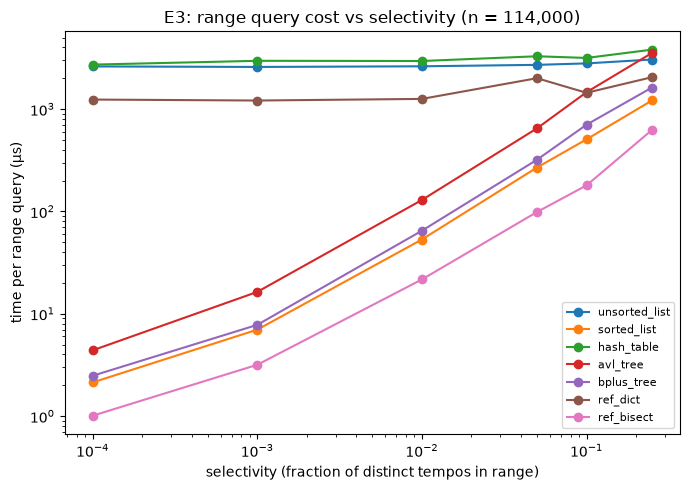

index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
operation_param,,,,,,,
0.0001,4.4,2.5,2719.7,1.0,1239.1,2.1,2611.4
0.0010,16.3,7.8,2962.8,3.2,1212.4,7.0,2580.5
0.0100,129.3,64.8,2949.5,21.6,1257.1,53.2,2618.3
0.0500,648.0,319.8,3282.1,98.7,2003.6,268.5,2705.0
0.1000,1461.7,703.3,3160.1,179.6,1442.4,506.3,2795.2
0.2500,3535.8,1625.1,3809.4,625.5,2049.7,1214.5,3050.6


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
operation_param,,,,,,,
0.0001,19.0,22.0,45653.0,NaN,NaN,22.0,114000.0
0.0010,60.0,63.0,45653.0,NaN,NaN,63.0,114000.0
0.0100,471.0,474.0,45653.0,NaN,NaN,474.0,114000.0
0.0500,2296.0,2300.0,45653.0,NaN,NaN,2300.0,114000.0
0.1000,4578.0,4582.0,45653.0,NaN,NaN,4582.0,114000.0
0.2500,11426.0,11430.0,45653.0,NaN,NaN,11430.0,114000.0


In [13]:
e3 = r[r['experiment'].str.startswith('E3')]
m3 = e3.groupby(['index_type', 'operation_param'])[['us_per_op', 'cmp_per_op']].median().reset_index()

plt.figure(figsize=(7, 5))
for idx in INDEXES:
    g = m3[m3['index_type'] == idx]
    plt.loglog(g['operation_param'], g['us_per_op'], 'o-', label=idx)
plt.xlabel('selectivity (fraction of distinct tempos in range)'); plt.ylabel('time per range query (µs)')
plt.title('E3: range query cost vs selectivity (n = 114,000)'); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/e3_range.png', dpi=150); plt.show()

display(m3.pivot(index='operation_param', columns='index_type', values='us_per_op').round(1))
display(m3.pivot(index='operation_param', columns='index_type', values='cmp_per_op').round(0))

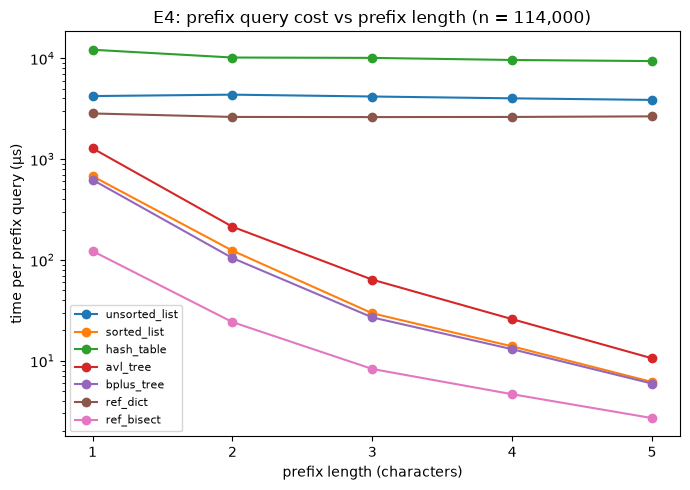

index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
operation_param,,,,,,,
1.0,1278.4,623.0,12145.1,122.4,2835.5,676.9,4218.3
2.0,213.4,104.4,10169.4,24.2,2618.4,123.6,4355.8
3.0,63.7,26.9,10084.4,8.3,2609.7,29.6,4175.6
4.0,25.9,13.0,9615.3,4.7,2618.5,13.9,4004.3
5.0,10.6,5.9,9375.4,2.7,2653.5,6.2,3863.1


In [14]:
e4 = r[r['experiment'].str.startswith('E4')]
m4 = e4.groupby(['index_type', 'operation_param'])[['us_per_op', 'cmp_per_op']].median().reset_index()

plt.figure(figsize=(7, 5))
for idx in INDEXES:
    g = m4[m4['index_type'] == idx]
    plt.semilogy(g['operation_param'], g['us_per_op'], 'o-', label=idx)
plt.xlabel('prefix length (characters)'); plt.ylabel('time per prefix query (µs)')
plt.title('E4: prefix query cost vs prefix length (n = 114,000)'); plt.legend(fontsize=8)
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout(); plt.savefig('figures/e4_prefix.png', dpi=150); plt.show()

display(m4.pivot(index='operation_param', columns='index_type', values='us_per_op').round(1))

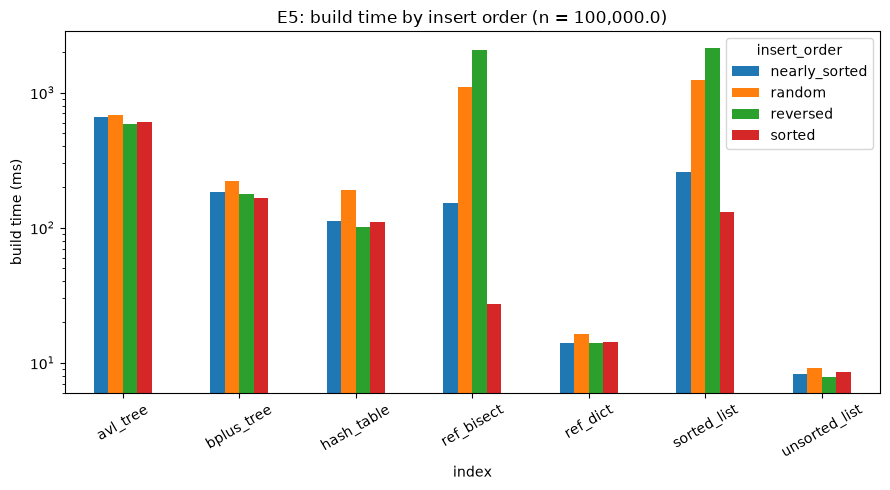

insert_order,nearly_sorted,random,reversed,sorted
index_type,,,,
avl_tree,664.0,678.7,590.0,609.7
bplus_tree,184.3,222.5,177.6,166.4
hash_table,111.7,189.5,102.0,109.5
ref_bisect,152.1,1098.5,2055.2,27.1
ref_dict,14.0,16.5,14.0,14.3
sorted_list,258.4,1235.9,2144.1,131.4
unsorted_list,8.2,9.1,7.9,8.5


height  rotations  splits
index_type insert_order                            
avl_tree   nearly_sorted    20.0   120055.0     0.0
           random           20.0    70144.0     0.0
           reversed         17.0    99983.0     0.0
           sorted           17.0    99983.0     0.0
bplus_tree nearly_sorted     4.0        0.0  6135.0
           random            4.0        0.0  4829.0
           reversed          4.0        0.0  6661.0
           sorted            4.0        0.0  6635.0

insert_order,nearly_sorted,random,reversed,sorted
index_type,,,,
avl_tree,1.06,1.53,1.10,1.08
bplus_tree,1.85,1.95,1.77,1.92
hash_table,0.70,0.78,0.68,0.69
ref_bisect,0.54,0.53,0.52,0.55
ref_dict,0.24,0.25,0.27,0.25
sorted_list,1.71,1.80,1.50,2.20
unsorted_list,1713.50,1698.59,1699.38,1750.07


In [15]:
e5 = r[r['experiment'].str.startswith('E5')]
big = e5[e5['n_keys'] == e5['n_keys'].max()]

build5 = big[big['operation'] == 'build'].groupby(['index_type', 'insert_order'])['total_ns'].median().unstack() / 1e6
build5.plot(kind='bar', logy=True, figsize=(9, 5))
plt.ylabel('build time (ms)'); plt.xlabel('index')
plt.title(f"E5: build time by insert order (n = {e5['n_keys'].max():,})")
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig('figures/e5_order.png', dpi=150); plt.show()
display(build5.round(1))

# tree shape and rebalancing work by order
shape = big[big['operation'] == 'build'].groupby(['index_type', 'insert_order'])[['height', 'rotations', 'splits']].median()
display(shape[shape.index.get_level_values(0).isin(['avl_tree', 'bplus_tree'])])

hit5 = big[big['operation'] == 'point_hit'].groupby(['index_type', 'insert_order'])['us_per_op'].median().unstack()
display(hit5.round(2))

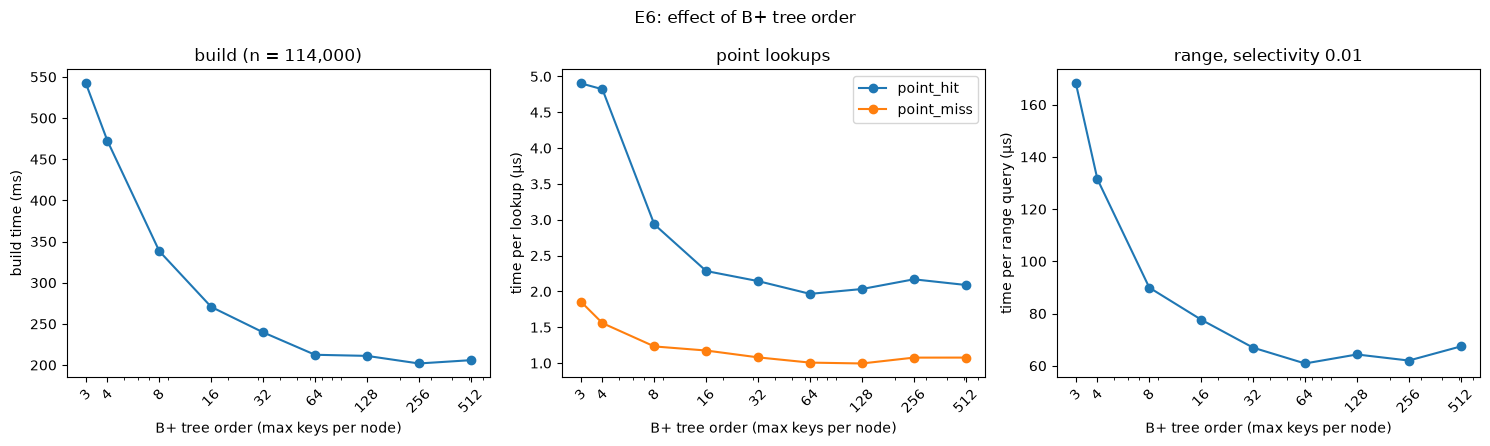

,order,build_ms,height,mem_MB
0,3,542.2,14.0,28.9
4,4,472.4,11.0,20.2
8,8,338.3,7.0,12.5
12,16,270.6,5.0,10.3
16,32,239.7,4.0,9.2
20,64,212.5,3.0,8.7
24,128,211.1,3.0,8.4
28,256,201.9,3.0,8.3
32,512,205.9,2.0,8.3


operation,point_hit,point_miss,range
order,,,
3,4.90,1.86,168.18
4,4.82,1.56,131.47
8,2.94,1.23,89.94
16,2.28,1.18,77.65
32,2.14,1.08,66.94
64,1.97,1.01,60.89
128,2.03,0.99,64.34
256,2.17,1.08,62.01
512,2.09,1.08,67.42


In [16]:
e6 = r[r['experiment'].str.startswith('E6')].copy()
e6['order'] = e6['index_param'].str.extract(r'(\d+)').astype(int)

m6 = e6.groupby(['order', 'operation']).agg(us=('us_per_op', 'median'), build_ms=('total_ns', lambda x: x.median() / 1e6),
                                            mem=('memory_bytes', 'median'), height=('height', 'median')).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
b = m6[m6['operation'] == 'build']
axes[0].semilogx(b['order'], b['build_ms'], 'o-'); axes[0].set_ylabel('build time (ms)'); axes[0].set_title('build (n = 114,000)')
for op in ['point_hit', 'point_miss']:
    g = m6[m6['operation'] == op]; axes[1].semilogx(g['order'], g['us'], 'o-', label=op)
axes[1].set_ylabel('time per lookup (µs)'); axes[1].set_title('point lookups'); axes[1].legend()
g = m6[m6['operation'] == 'range']
axes[2].semilogx(g['order'], g['us'], 'o-'); axes[2].set_ylabel('time per range query (µs)'); axes[2].set_title('range, selectivity 0.01')
for ax in axes: ax.set_xlabel('B+ tree order (max keys per node)'); ax.set_xticks(sorted(e6['order'].unique())); ax.set_xticklabels(sorted(e6['order'].unique()), rotation=45)
plt.suptitle('E6: effect of B+ tree order'); plt.tight_layout(); plt.savefig('figures/e6_order.png', dpi=150); plt.show()

display(b[['order', 'build_ms', 'mem', 'height']].assign(mem_MB=lambda d: (d['mem'] / 1e6).round(1)).drop(columns='mem').round(1))
display(m6[m6['operation'] != 'build'].pivot(index='order', columns='operation', values='us').round(2))

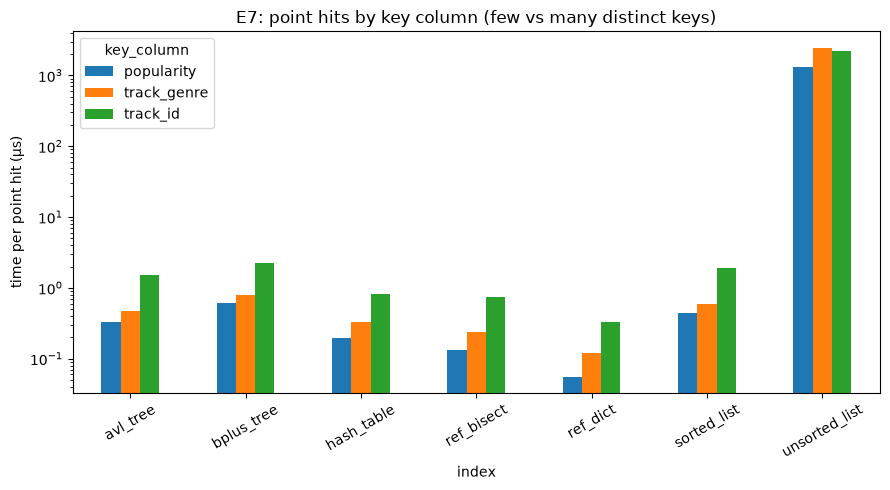

build (ms)


key_column,popularity,track_genre,track_id
index_type,,,
avl_tree,210.7,236.1,787.8
bplus_tree,87.0,83.1,272.3
hash_table,34.2,41.4,86.7
ref_bisect,17.3,21.9,932.2
ref_dict,9.8,13.4,21.4
sorted_list,58.0,58.2,1046.4
unsorted_list,9.3,11.8,11.2


point hit (µs)


key_column,popularity,track_genre,track_id
index_type,,,
avl_tree,0.33,0.47,1.51
bplus_tree,0.61,0.79,2.22
hash_table,0.20,0.33,0.81
ref_bisect,0.13,0.24,0.74
ref_dict,0.06,0.12,0.33
sorted_list,0.44,0.59,1.89
unsorted_list,1292.33,2452.49,2243.02


point miss (µs)


key_column,popularity,track_genre,track_id
index_type,,,
avl_tree,0.35,0.40,0.87
bplus_tree,0.56,0.69,1.20
hash_table,0.19,0.26,0.51
ref_bisect,0.10,0.17,0.16
ref_dict,0.06,0.09,0.22
sorted_list,0.36,0.53,0.92
unsorted_list,1524.55,2465.23,2377.80


popularity range (µs)


operation_param,0.01,0.05,0.10,0.25
index_type,,,,
avl_tree,4.8,20.3,40.6,118.7
bplus_tree,4.4,20.3,38.7,108.4
hash_table,10.8,26.3,45.5,118.6
ref_bisect,4.0,19.1,38.5,112.8
ref_dict,5.4,20.8,40.9,114.0
sorted_list,2.8,15.5,34.1,80.7
unsorted_list,1819.7,1866.7,1916.8,2122.2


In [17]:
e7 = r[r['experiment'].str.startswith('E7')]

build7 = e7[e7['operation'] == 'build'].groupby(['index_type', 'key_column'])['total_ns'].median().unstack() / 1e6
hit7 = e7[e7['operation'] == 'point_hit'].groupby(['index_type', 'key_column'])['us_per_op'].median().unstack()
miss7 = e7[e7['operation'] == 'point_miss'].groupby(['index_type', 'key_column'])['us_per_op'].median().unstack()

hit7.plot(kind='bar', logy=True, figsize=(9, 5))
plt.ylabel('time per point hit (µs)'); plt.xlabel('index')
plt.title('E7: point hits by key column (few vs many distinct keys)')
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig('figures/e7_duplicates.png', dpi=150); plt.show()

print("build (ms)"); display(build7.round(1))
print("point hit (µs)"); display(hit7.round(2))
print("point miss (µs)"); display(miss7.round(2))

# popularity range queries
rng7 = e7[e7['operation'] == 'range'].groupby(['index_type', 'operation_param'])['us_per_op'].median().unstack()
print("popularity range (µs)"); display(rng7.round(1))